# 01 — EDA i kontrakt danych (Sprint 1)

Cel notebooka: poznać dane wybranego datasetu i podjąć decyzje, które trafią do kodu:

- **input normalization** — reguły w `normalize_input()` (`src/asi_project/data.py`),
- **training-only filtering** — reguły w `filter_training_rows()` (jeśli są potrzebne),
- **typy cech** — listy `features.numeric` i `features.categorical` w `project.yaml`,
- **metryka główna** — uzasadnienie w karcie projektu w README.

Jak pracować:

- uruchamiajcie notebook od góry (Restart & Run All); po zmianie `project.yaml` uruchomcie
  ponownie komórkę ustawień,
- komórki oznaczone **TODO** uzupełnia zespół; odpowiedzi tekstowe wpisujcie w miejsce
  `*(odpowiedź)*`,
- nie zmieniajcie kontraktu prowadzącej (`src/asi_project/datasets.yaml`).

## 0. Ustawienia

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

from asi_project.config import get_contract, load_project_config
from asi_project.data import (
    encode_target,
    feature_list_problems,
    filter_training_rows,
    is_text_column,
    load_dataset,
    normalize_input,
    target_classes,
    validate,
)

config = load_project_config()
contract = get_contract(config)
DATA_MODE = os.environ.get("ASI_DATA_MODE", "full")

print(f"Dataset: {contract.title} ({contract.dataset_id})")
print(f"Target: {contract.target} | klasa pozytywna: {contract.positive_class}")
print(f"Moment predykcji: {contract.prediction_moment}")

Dataset: Bank Loan Status (bank_loan_status)
Target: Loan Status | klasa pozytywna: Charged Off
Moment predykcji: Predykcja w chwili rozpatrywania wniosku kredytowego, na podstawie parametrów kredytu i historii kredytowej klienta, zanim wiadomo, czy kredyt zostanie spłacony.


## 1. Wczytanie danych

Pełne dane pobiera `python scripts/download_data.py`. Nazwy kolumn są ujednolicane przy
wczytywaniu (białe znaki), wartości — jeszcze nie.

In [2]:
df_raw = load_dataset(config, contract, mode=DATA_MODE)
print(df_raw.shape)
df_raw.head()

(100514, 19)


,Loan ID,Customer ID,Loan Status,Current Loan Amount,Term,Credit Score,Annual Income,Years in current job,Home Ownership,Purpose,Monthly Debt,Years of Credit History,Months since last delinquent,Number of Open Accounts,Number of Credit Problems,Current Credit Balance,Maximum Open Credit,Bankruptcies,Tax Liens
0,14dd8831-6af5-400b-83ec-68e61888a048,981165ec-3274-42f5-a3b4-d104041a9ca9,Fully Paid,445412.0,Short Term,709.0,1167493.0,8 years,Home Mortgage,Home Improvements,5214.74,17.2,NaN,6.0,1.0,228190.0,416746.0,1.0,0.0
1,4771cc26-131a-45db-b5aa-537ea4ba5342,2de017a3-2e01-49cb-a581-08169e83be29,Fully Paid,262328.0,Short Term,NaN,NaN,10+ years,Home Mortgage,Debt Consolidation,33295.98,21.1,8.0,35.0,0.0,229976.0,850784.0,0.0,0.0
2,4eed4e6a-aa2f-4c91-8651-ce984ee8fb26,5efb2b2b-bf11-4dfd-a572-3761a2694725,Fully Paid,99999999.0,Short Term,741.0,2231892.0,8 years,Own Home,Debt Consolidation,29200.53,14.9,29.0,18.0,1.0,297996.0,750090.0,0.0,0.0
3,77598f7b-32e7-4e3b-a6e5-06ba0d98fe8a,e777faab-98ae-45af-9a86-7ce5b33b1011,Fully Paid,347666.0,Long Term,721.0,806949.0,3 years,Own Home,Debt Consolidation,8741.90,12.0,NaN,9.0,0.0,256329.0,386958.0,0.0,0.0
4,d4062e70-befa-4995-8643-a0de73938182,81536ad9-5ccf-4eb8-befb-47a4d608658e,Fully Paid,176220.0,Short Term,NaN,NaN,5 years,Rent,Debt Consolidation,20639.70,6.1,NaN,15.0,0.0,253460.0,427174.0,0.0,0.0


## 2. Inspekcja: typy, braki, liczba unikalnych wartości

In [3]:
# DONE
# Obserwacje: które kolumny mają nieoczekiwany typ? Gdzie są braki?
# Które kolumny liczbowe są w rzeczywistości kategoriami?

df_nonempty = df_raw.dropna(how="all")
print(f"Wiersze w całości NaN: {len(df_raw) - len(df_nonempty)} ==> nowe n = {len(df_nonempty)}")
same_mask = df_nonempty["Credit Score"].isna().equals(df_nonempty["Annual Income"].isna())
print("maska NaN: Credit Score == Annual Income:", same_mask)

print("\nObserwacje po usunięciu wierszy w całości NaN:")
numeric = df_nonempty.select_dtypes("number")
text = df_nonempty.select_dtypes("object")


def levels(col):
    n = col.nunique()
    if n <= 4:
        return col.value_counts().to_dict()
    elif n <= 20:
        head = col.value_counts().head(2)
        tail = col.value_counts().tail(-2)
        return f"{head.to_dict()}, ... ({len(tail)} others)"
    else:
        return "..."


observations = pd.DataFrame(
    {
        "dtype": df_nonempty.dtypes.astype(str),
        "NaN": df_nonempty.isna().sum(),
        "NaN %": (df_nonempty.isna().mean() * 100).round(1),
        "unikalne": df_nonempty.nunique(),
        "całkowite": numeric.apply(lambda col: (col.dropna() % 1 == 0).all()),
        "poziomy": text.apply(levels),
    },
).reindex(df_nonempty.columns)
observations

Wiersze w całości NaN: 514 ==> nowe n = 100000
maska NaN: Credit Score == Annual Income: True

Obserwacje po usunięciu wierszy w całości NaN:


,dtype,NaN,NaN %,unikalne,całkowite,poziomy
Loan ID,object,0,0.0,81999,NaN,...
Customer ID,object,0,0.0,81999,NaN,...
Loan Status,object,0,0.0,2,NaN,"{'Fully Paid': 77361, 'Charged Off': 22639}"
Current Loan Amount,float64,0,0.0,22004,True,NaN
Term,object,0,0.0,2,NaN,"{'Short Term': 72208, 'Long Term': 27792}"
Credit Score,float64,19154,19.2,324,True,NaN
Annual Income,float64,19154,19.2,36174,True,NaN
Years in current job,object,4222,4.2,11,NaN,"{'10+ years': 31121, '2 years': 9134}, ... (9 ..."
Home Ownership,object,0,0.0,4,NaN,"{'Home Mortgage': 48410, 'Rent': 42194, 'Own H..."
Purpose,object,0,0.0,16,NaN,"{'Debt Consolidation': 78552, 'other': 6037}, ..."


## 3. Kontrakt danych

Kontrakt prowadzącej określa target, klasę pozytywną, ALLOWED FEATURES (jedyne kolumny
dozwolone w X) i EXCLUDED FEATURES wraz z powodem wykluczenia.

In [4]:
problems = validate(df_raw, contract)
print("Kontrakt danych:", "OK" if not problems else problems)
print("ALLOWED FEATURES:", list(contract.allowed_features))
print("EXCLUDED FEATURES:")
for column, reason in contract.excluded_features.items():
    status = "jest w danych" if column in df_raw.columns else "brak w pliku"
    print(f"- {column} ({status}): {reason}")

Kontrakt danych: OK
ALLOWED FEATURES: ['Current Loan Amount', 'Term', 'Credit Score', 'Annual Income', 'Years in current job', 'Home Ownership', 'Purpose', 'Monthly Debt', 'Years of Credit History', 'Months since last delinquent', 'Number of Open Accounts', 'Number of Credit Problems', 'Current Credit Balance', 'Maximum Open Credit', 'Bankruptcies', 'Tax Liens']
EXCLUDED FEATURES:
- Loan ID (jest w danych): identyfikator kredytu (potrzebny tylko do deduplikacji rekordów)
- Customer ID (jest w danych): identyfikator klienta


## 4. Target i klasa pozytywna

Klasy targetu: ['charged off', 'fully paid']
Klasa pozytywna: 'Charged Off'
Udział klasy pozytywnej: 0.226


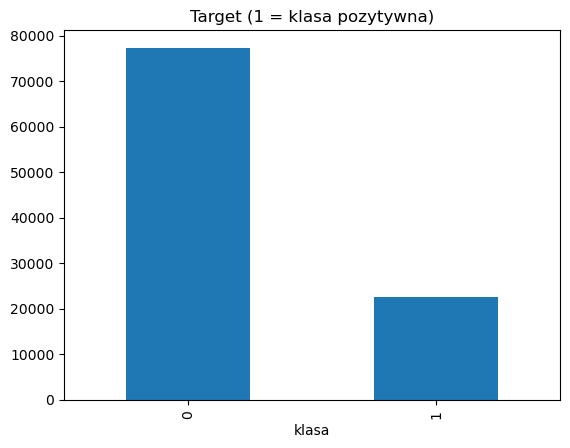

In [5]:
print("Klasy targetu:", target_classes(df_raw[contract.target]))
print("Klasa pozytywna:", repr(contract.positive_class))
y = encode_target(df_raw[contract.target].dropna(), contract.positive_class)
print(f"Udział klasy pozytywnej: {y.mean():.3f}")
ax = y.value_counts().sort_index().plot(kind="bar", title="Target (1 = klasa pozytywna)")
ax.set_xlabel("klasa")
plt.show()

**DONE — metryka główna (2–3 zdania):** którą metrykę (accuracy, precision, recall, F1)
wybieracie jako główną i dlaczego, biorąc pod uwagę udział klasy pozytywnej i koszt błędów
w waszym problemie? To samo uzasadnienie wpiszcie do karty projektu w README.

**Metryka główna: F1 dla klasy `Charged Off`** (udział klasy pozytywnej: 0,226)

| metryka | ocena |
|---|---|
| accuracy | odrzucona: model trywialny przewidujący "zawsze `Fully Paid`" daje 0,774 bez żadnej wiedzy |
| recall | ważna (FN = niewykryty kredyt niespłacony, koszt ~ zainwestowany kapitał), ale sama metryka jest maksymalizowana przez "zawsze `Charged Off`" |
| precision | ważna (FP = odrzucony dobry klient, koszt ~ utracona marża), ale sama nagradza bardzo ostrożny model |
| **F1** | **wybrana**: łączy recall i precision dla klasy pozytywnej, odporna na niezbalansowanie 77/23 |

## 5. EDA

**DONE:** co najmniej dwie analizy — jedna dla cechy numerycznej, jedna dla kategorycznej.
Wybierajcie wyłącznie spośród ALLOWED FEATURES.

In [6]:
# Cecha numeryczna: Credit Score w podziale na klasy targetu
df_nonempty.groupby(contract.target)["Credit Score"].describe()

,count,mean,std,min,25%,50%,75%,max
Loan Status,,,,,,,,
Charged Off,17210.0,2402.296862,2826.692993,585.0,705.0,730.0,6500.0,7510.0
Fully Paid,63636.0,717.889874,27.221750,585.0,705.0,723.0,739.0,751.0


In [7]:
# Cecha kategoryczna: udział klasy pozytywnej w kategoriach Term
pd.crosstab(df_nonempty["Term"], df_nonempty[contract.target], normalize="index").round(3)

Loan Status,Charged Off,Fully Paid
Term,,
Long Term,0.301,0.699
Short Term,0.198,0.802


In [8]:
pd.crosstab(df_nonempty["Term"], df_nonempty[contract.target], normalize="columns").round(3)

Loan Status,Charged Off,Fully Paid
Term,,
Long Term,0.37,0.251
Short Term,0.63,0.749


**DONE — wnioski z EDA (3–5 zdań):**

- `Credit Score`: `Fully Paid` ma max 751, a `Charged Off` max 7 510 -> część wyników w `Charged Off` jest zapisana w innej skali.
- `Long Term` ma więcej `Charged Off` niż `Short Term` (0,301 vs 0,198).
- Klasa pozytywna `Charged Off` to (niewielka część) 0,226 danych.
- 514 wierszy w całości NaN; `Credit Score` i `Annual Income` mają braki w tych samych wierszach. Prawdopodobnie bez przychodu nie można było obliczyć punktów.
- `Home Ownership` ma dwa zapisy jednej kategorii: `HaveMortgage` i `Home Mortgage`.

## 6. Input normalization

Input normalization działa na pojedynczym rekordzie, nie używa targetu ani statystyk zbioru
i jest idempotentna. Typowe kandydatki: białe znaki, puste napisy, oczywiste reprezentacje
braków, ujednolicenie zapisu wartości. Uzupełnianie braków medianą **nie jest** input
normalization — wymaga `fit`, więc należy do model preprocessing.

In [9]:
text_columns = [column for column in df_raw.columns if is_text_column(df_raw[column])]
for column in text_columns:
    values = df_raw[column].dropna().astype(str)
    padded = int((values != values.str.strip()).sum())
    empty = int((values.str.strip() == "").sum())
    top = values.value_counts().head(6).to_dict()
    print(f"{column}: spacje na brzegach={padded}, puste={empty}, najczęstsze={top}")

Loan ID: spacje na brzegach=0, puste=0, najczęstsze={'7aa649ff-b73b-4556-a4c3-a4d35762809a': 2, '578c8e10-3214-4491-bdbc-b1695ef8ff87': 2, '0c14cb77-29a3-4964-9198-0c43f5f982b0': 2, '24e8c8bd-d10b-4dac-8b81-1da470ff5ecb': 2, '7cbaa3fa-16fd-4343-9bcb-e90b34a1072f': 2, 'f8dcf551-d7b6-4378-8a29-caa1b0a42e75': 2}
Customer ID: spacje na brzegach=0, puste=0, najczęstsze={'54f57722-2473-4dd8-b69b-82b5b0c1c9f9': 2, 'cbe53e22-ba67-4eaf-a4fb-c5acdd12ec66': 2, '9baf6d5d-f744-4332-abb0-e939b75cde40': 2, '967e8733-7189-49b7-a3ab-6a1d0e1abdac': 2, '3ec886e7-f15d-4c35-83d0-bdec4817ae4b': 2, 'b6f9e737-6609-45fd-8d6c-37b1b64c45df': 2}
Loan Status: spacje na brzegach=0, puste=0, najczęstsze={'Fully Paid': 77361, 'Charged Off': 22639}
Term: spacje na brzegach=0, puste=0, najczęstsze={'Short Term': 72208, 'Long Term': 27792}
Years in current job: spacje na brzegach=0, puste=0, najczęstsze={'10+ years': 31121, '2 years': 9134, '3 years': 8169, '< 1 year': 8164, '5 years': 6787, '1 year': 6460}
Home Ownersh

**DONE — reguły input normalization:** jakie reguły dopisujecie do `normalize_input()` i dlaczego
są bezpieczne przy predykcji pojedynczego rekordu? Po zmianie funkcji uruchomcie `pytest`.

- W `Purpose` zamieniamy `other` na `Other`, bo to ta sama kategoria zapisana na dwa sposoby.
- W `Credit Score` dzielimy przez 10 wartości czterocyfrowe, bo to zwykłe wyniki z dopisanym zerem: po podzieleniu mają ten sam zakres co pozostałe.
- Reguły są bezpieczne: dziłają na tylko jednym polu, nie używają targetu ani statystyk, są idempotentne.

In [10]:
normalized = normalize_input(df_raw)
changed = (normalized.astype(str) != df_raw.astype(str)).sum()
changed[changed > 0]

Credit Score    4551
Purpose         6037
dtype: int64

## 7. Training-only filtering

Training-only filtering działa tylko przy przygotowaniu danych treningowych i może jedynie
usuwać rekordy. Domyślnie `filter_training_rows()` usuwa rekordy bez targetu.

In [11]:
print("Rekordy bez targetu:", int(df_raw[contract.target].isna().sum()))
print("Dokładne duplikaty wierszy:", int(df_raw.duplicated().sum()))
filtered = filter_training_rows(normalize_input(df_raw), contract)
print(f"Po training-only filtering: {len(filtered)} z {len(df_raw)} rekordów")

Rekordy bez targetu: 514
Dokładne duplikaty wierszy: 10728
Po training-only filtering: 89785 z 100514 rekordów


**DONE — decyzja o training-only filtering:** czy usuwacie dodatkowo jakieś rekordy
(np. dokładne duplikaty)? Dlaczego tak albo dlaczego nie?

- Tak, usuwamy dokładne duplikaty wierszy, bo ten sam kredyt zapisany kilka razy ma w treningu większą wagę.
  Na dodatek, może trafić jednocześnie do zbioru treningowego i testowego.

## 8. Typy cech → `project.yaml`

**DONE:** wpiszcie do `project.yaml` listy `features.numeric` i `features.categorical`
(wyłącznie ALLOWED FEATURES), zapiszcie plik i uruchomcie ponownie komórkę ustawień oraz
komórkę poniżej.

In [12]:
print("Numeryczne:", list(config.numeric_features))
print("Kategoryczne:", list(config.categorical_features))
print("Problemy z deklaracją:", feature_list_problems(contract, config.model_features) or "brak")
print("Kontrakt z deklaracją:", validate(normalize_input(df_raw), contract, config) or "OK")

Numeryczne: ['Current Loan Amount', 'Credit Score', 'Annual Income', 'Monthly Debt', 'Years of Credit History', 'Months since last delinquent', 'Number of Open Accounts', 'Number of Credit Problems', 'Current Credit Balance', 'Maximum Open Credit', 'Bankruptcies', 'Tax Liens']
Kategoryczne: ['Term', 'Years in current job', 'Home Ownership', 'Purpose']
Problemy z deklaracją: brak
Kontrakt z deklaracją: OK


## 9. Podsumowanie decyzji

**DONE — w 3–5 punktach:** decyzje o input normalization, training-only filtering, typach cech
i metryce głównej. Te decyzje będą punktem wyjścia do ADR-1 w Sprincie 2.

- Input normalization: w `Purpose` zamieniamy `other` na `Other`, a w `Credit Score` dzielimy przez 10 wartości czterocyfrowe.
- Training-only filtering: oprócz rekordów bez targetu usuwamy dokładne duplikaty wierszy.
- Typy cech: 4 kolumny tekstowe są kategoryczne, pozostałe 12 numeryczne.
- Metryka główna: F1 dla klasy `Charged Off`, bo accuracy przy niezbalansowanych klasach nagradza model, który zawsze przewiduje `Fully Paid`.